# Duplicate Question Retrieval on Quora

**Goal:** given a new question, find questions in the collection that ask the same thing.

We compare four ranking models (TF-IDF, BM25, Sentence Transformer, Hybrid RRF) on the
BEIR Quora Question Pairs dataset and evaluate them with P@10, Recall@10, MAP and nDCG@10.

In [1]:
# On Google Colab, uncomment the next line to install the libraries first
# !pip install -q datasets nltk scikit-learn rank_bm25 sentence-transformers

import os, re, math, json, random, pickle, string, zipfile, urllib.request
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from datasets import load_dataset
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

nltk.download("stopwords", quiet=True)

NUM_QUERIES = 500      # number of test queries we evaluate on
CORPUS_SIZE = 50_000   # number of questions in our search collection
SEED = 42

W1025 20:27:27.933000 19273 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Step 1: Load the data

We use the **BEIR version of Quora Question Pairs**: a corpus of unique Quora questions, a set of
query questions, and *qrels* that list which corpus questions are duplicates of each query.
To keep things fast we take 5000 random test queries and a 50,000-question corpus that contains all
their duplicates plus random other questions. The subset is saved to a pickle file so it loads instantly next time.

In [2]:
def load_from_huggingface():
    corpus_ds = load_dataset("BeIR/quora", "corpus")
    queries_ds = load_dataset("BeIR/quora", "queries")
    qrels_ds = load_dataset("BeIR/quora-qrels")
    # Print the available splits
    print(corpus_ds, queries_ds, qrels_ds, sep="\n")

    corpus = dict(zip(corpus_ds["corpus"]["_id"], corpus_ds["corpus"]["text"]))
    queries = dict(zip(queries_ds["queries"]["_id"], queries_ds["queries"]["text"]))
    test = qrels_ds["test"]
    qrels = defaultdict(set)
    for qid, did, score in zip(test["query-id"], test["corpus-id"], test["score"]):
        if score > 0:
            qrels[str(qid)].add(str(did))   # IDs are ints in qrels, strings in the corpus
    return corpus, queries, qrels


def load_from_beir_zip():
    # Backup plan: download the original BEIR zip file
    url = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/quora.zip"
    if not os.path.exists("quora.zip"):
        urllib.request.urlretrieve(url, "quora.zip")
    with zipfile.ZipFile("quora.zip") as z:
        print("Files in zip:", z.namelist())
        read_jsonl = lambda name: [json.loads(line) for line in z.read(name).decode().splitlines()]
        corpus = {r["_id"]: r["text"] for r in read_jsonl("quora/corpus.jsonl")}
        queries = {r["_id"]: r["text"] for r in read_jsonl("quora/queries.jsonl")}
        qrels = defaultdict(set)
        for line in z.read("quora/qrels/test.tsv").decode().splitlines()[1:]:   # skip header
            qid, did, score = line.split("\t")
            if int(score) > 0:
                qrels[qid].add(did)
    return corpus, queries, qrels


def build_subset():
    try:
        corpus, queries, qrels = load_from_huggingface()
    except Exception as e:
        print("HuggingFace failed:", e, "-> using the BEIR zip instead")
        corpus, queries, qrels = load_from_beir_zip()

    random.seed(SEED)
    query_ids = random.sample(sorted(qrels), NUM_QUERIES)

    # Every duplicate of the sampled queries must be in our corpus
    needed = sorted({d for q in query_ids for d in qrels[q]})
    needed_set = set(needed)
    others = [d for d in corpus if d not in needed_set]
    extra = random.sample(others, CORPUS_SIZE - len(needed))
    doc_ids = needed + extra

    return {
        "doc_ids": doc_ids,
        "doc_texts": [corpus[d] for d in doc_ids],
        "queries": {q: queries[q] for q in query_ids},
        "qrels": {q: qrels[q] for q in query_ids},
    }


if os.path.exists("quora_subset.pkl"):
    subset = pickle.load(open("quora_subset.pkl", "rb"))
    print("Loaded saved subset from quora_subset.pkl")
else:
    subset = build_subset()
    pickle.dump(subset, open("quora_subset.pkl", "wb"))
    print("Saved subset to quora_subset.pkl")

doc_ids, doc_texts = subset["doc_ids"], subset["doc_texts"]
queries, qrels = subset["queries"], subset["qrels"]
id_to_text = dict(zip(doc_ids, doc_texts))

Loaded saved subset from quora_subset.pkl


In [3]:
# Basic statistics
avg_len = lambda texts: np.mean([len(t.split()) for t in texts])
print("Number of documents (corpus questions):", len(doc_ids))
print("Number of queries:", len(queries))
print("Average duplicates per query: %.2f" % np.mean([len(r) for r in qrels.values()]))
print("Average question length (words): corpus %.1f, queries %.1f"
      % (avg_len(doc_texts), avg_len(queries.values())))

# Three example queries with their duplicates
for qid in list(queries)[:3]:
    print("\nQUERY:", queries[qid])
    for d in qrels[qid]:
        print("   duplicate:", id_to_text[d])

Number of documents (corpus questions): 50000
Number of queries: 500
Average duplicates per query: 1.40
Average question length (words): corpus 11.5, queries 9.4

QUERY: Is there bull sperms in red bull?
   duplicate: Does red bull energy drink have bull sperm in it?
   duplicate: Do energy drinks (such as Red Bull) have bull sperm in it?
   duplicate: Is Red Bull energy drink made by bull sperm?
   duplicate: Does Red Bull contain bull sperm?
   duplicate: Does red bull drink contain bull sperm?
   duplicate: Do energy drinks have bull sperms?

QUERY: Will the universe end?
   duplicate: Does the universe have any end? If not, then why?
   duplicate: Does the universe ever end?

QUERY: Which test series is best for gate?
   duplicate: Which is the best test series for gate?


## Step 2: Text preprocessing

Each question is cleaned in five steps: **lowercase → remove punctuation → tokenize → remove stop words → Porter stemming**.
We keep question words such as *what, why, how* and the word *not* out of the stop-word list,
because "how to learn python" and "why learn python" are different questions.

In [4]:
# Keep words that change the meaning of a question
KEEP_WORDS = {"what", "why", "how", "when", "where", "who", "which", "whom", "not", "no"}
STOP_WORDS = set(stopwords.words("english")) - KEEP_WORDS
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()                                              # 1. lowercase
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)   # 2. remove punctuation
    tokens = text.split()                                            # 3. tokenize
    tokens = [t for t in tokens if t not in STOP_WORDS]              # 4. remove stop words
    return [stemmer.stem(t) for t in tokens]                         # 5. stemming

example = doc_texts[0]
print("Before:", example)
print("After: ", preprocess(example))

Before: What are some examples of cultural relativism?
After:  ['what', 'exampl', 'cultur', 'relativ']


In [5]:
# Preprocess the whole corpus once
doc_tokens = [preprocess(t) for t in doc_texts]
print("Preprocessed", len(doc_tokens), "documents")

Preprocessed 50000 documents


## Step 3: Inverted index

An inverted index maps every term to the list of documents that contain it (its *postings list*).
This is the core data structure of search engines: to answer a query we only need to look at the
documents in the postings of the query terms, not the whole collection.

In [6]:
inverted_index = defaultdict(list)
for doc_id, tokens in zip(doc_ids, doc_tokens):
    for term in set(tokens):
        inverted_index[term].append(doc_id)

print("Vocabulary size:", len(inverted_index))
for term in ["python", "invest", "learn"]:
    postings = inverted_index[term]
    print(f"\n'{term}' appears in {len(postings)} docs. First 10 postings: {postings[:10]}")

# Example: which documents contain ALL terms of a query?
q_terms = preprocess("How do I learn Python?")
matches = set.intersection(*[set(inverted_index[t]) for t in q_terms])
print(f"\nDocs containing all of {q_terms}: {len(matches)}")
for d in list(matches)[:3]:
    print("  ", id_to_text[d])

Vocabulary size: 21347

'python' appears in 84 docs. First 10 postings: ['251858', '524893', '97722', '309686', '134529', '330605', '459541', '16072', '235309', '392573']

'invest' appears in 227 docs. First 10 postings: ['173308', '303476', '307079', '330504', '534853', '71513', '72649', '258177', '225341', '450113']

'learn' appears in 930 docs. First 10 postings: ['127648', '186800', '19350', '208476', '264627', '264628', '283716', '312968', '313322', '383095']

Docs containing all of ['how', 'learn', 'python']: 7
   How can I learn about python on my own?
   How long would it take a coding newbie to learn their first programming language (Python, Java, C etc)?
   In how much time can I learn Python?


### Helper: take the top-k results

All models give one score per document. This helper sorts the scores and returns the top-k `(doc_id, score)` pairs.
Because a query can also appear in the corpus, it would match itself, so we **remove the result whose ID equals the query ID**.

In [7]:
def top_k(scores, k=100, exclude_id=None):
    best = np.argsort(-scores)[:k + 1]   # one extra in case we drop the query itself
    results = [(doc_ids[i], float(scores[i])) for i in best if doc_ids[i] != exclude_id]
    return results[:k]

def show(results):
    # print results as "score  question text"
    for doc_id, score in results:
        print(f"{score:.4f}  {id_to_text[doc_id]}")

## Step 4: TF-IDF

TF-IDF gives a high weight to words that are frequent in a question but rare in the collection.
Every question becomes a sparse vector, and we rank documents by **cosine similarity** with the query vector.

In [8]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform([" ".join(t) for t in doc_tokens])
print("TF-IDF matrix shape (docs x terms):", tfidf_matrix.shape)

def search_tfidf(query, k=100, exclude_id=None):
    query_vec = tfidf_vectorizer.transform([" ".join(preprocess(query))])
    scores = cosine_similarity(query_vec, tfidf_matrix).ravel()
    return top_k(scores, k, exclude_id)

show(search_tfidf("How do I learn Python?", k=3))

TF-IDF matrix shape (docs x terms): (50000, 21059)
1.0000  How can I learn about python on my own?
0.9053  Why should I learn Python?
0.8225  How do I learn Python at home?


## Step 5: BM25

BM25 is a probabilistic ranking function that improves on TF-IDF in two ways: term frequency *saturates*
(the 5th occurrence of a word adds less than the 1st), and long documents are normalized by length.
We use `BM25Okapi` from the `rank_bm25` library on the preprocessed tokens.

In [9]:
bm25 = BM25Okapi(doc_tokens)

def search_bm25(query, k=100, exclude_id=None):
    scores = bm25.get_scores(preprocess(query))
    return top_k(scores, k, exclude_id)

show(search_bm25("How do I learn Python?", k=3))

15.2574  How can I learn about python on my own?
14.0133  How do I learn Python at home?
14.0133  How can you learn Python algorithms?


## Step 6: Sentence Transformer (dense retrieval)

A neural model (`all-MiniLM-L6-v2`) turns each question into a 384-dimensional vector that captures its *meaning*,
so it can match questions that use different words. We feed it the **raw text** (no preprocessing) and rank by
cosine similarity. The embeddings are saved with `np.save` so they are computed only once.

In [10]:
model = SentenceTransformer("all-MiniLM-L6-v2")

if os.path.exists("corpus_emb.npy"):
    corpus_emb = np.load("corpus_emb.npy")
    print("Loaded saved embeddings")
else:
    # normalize_embeddings=True means cosine similarity = dot product
    corpus_emb = model.encode(doc_texts, batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    np.save("corpus_emb.npy", corpus_emb)
print("Embedding matrix shape:", corpus_emb.shape)

def search_dense(query, k=100, exclude_id=None):
    query_emb = model.encode(query, normalize_embeddings=True)
    scores = corpus_emb @ query_emb
    return top_k(scores, k, exclude_id)

show(search_dense("How do I learn Python?", k=3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded saved embeddings
Embedding matrix shape: (50000, 384)


0.9208  What's the best way to learn Python?
0.8921  How can I learn about python on my own?
0.8597  How do I learn Python at home?


## Step 7: Hybrid with Reciprocal Rank Fusion (RRF)

RRF combines several ranked lists using only the **ranks**, not the scores (which are on different scales).
Each document gets `score = sum over models of 1 / (60 + rank)`. We fuse the top-100 lists of TF-IDF, BM25 and Dense.

In [11]:
def rrf_fuse(result_lists, k=100, c=60):
    fused = defaultdict(float)
    for results in result_lists:
        for rank, (doc_id, _) in enumerate(results, start=1):
            fused[doc_id] += 1 / (c + rank)
    return sorted(fused.items(), key=lambda x: -x[1])[:k]

def search_hybrid(query, k=100, exclude_id=None):
    lists = [search_tfidf(query, 100, exclude_id), search_bm25(query, 100, exclude_id),
             search_dense(query, 100, exclude_id)]
    return rrf_fuse(lists, k)

show(search_hybrid("How do I learn Python?", k=3))

0.0489  How can I learn about python on my own?
0.0479  How do I learn Python at home?
0.0458  Why should I learn Python?


In [12]:
# Save everything the Streamlit app needs
pickle.dump((tfidf_vectorizer, tfidf_matrix), open("tfidf.pkl", "wb"))
pickle.dump(bm25, open("bm25.pkl", "wb"))
print("Saved tfidf.pkl, bm25.pkl (embeddings already in corpus_emb.npy)")

Saved tfidf.pkl, bm25.pkl (embeddings already in corpus_emb.npy)


## Step 8: Evaluation

We run all 500 queries through the four models (top-100 results each) and compare them with the qrels:
- **P@10**: fraction of the top-10 results that are duplicates (low for every model, because most queries have only 1-2 duplicates)
- **Recall@10**: fraction of all duplicates found in the top 10
- **MAP**: mean of Average Precision (computed over the top-100 list), rewards finding duplicates early
- **nDCG@10**: like P@10 but hits near the top count more (logarithmic discount)

In [13]:
# Run all queries through all models (the query itself is excluded from its results)
runs = {"TF-IDF": {}, "BM25": {}, "Sentence Transformer": {}, "Hybrid RRF": {}}
for qid, text in queries.items():
    tfidf_res = search_tfidf(text, 100, exclude_id=qid)
    bm25_res = search_bm25(text, 100, exclude_id=qid)
    dense_res = search_dense(text, 100, exclude_id=qid)
    hybrid_res = rrf_fuse([tfidf_res, bm25_res, dense_res], 100)
    for name, res in zip(runs, [tfidf_res, bm25_res, dense_res, hybrid_res]):
        runs[name][qid] = [doc_id for doc_id, _ in res]
print("Done: ranked", len(queries), "queries with", len(runs), "models")

Done: ranked 500 queries with 4 models


In [14]:
def precision_at_k(ranked, relevant, k=10):
    return sum(d in relevant for d in ranked[:k]) / k

def recall_at_k(ranked, relevant, k=10):
    return sum(d in relevant for d in ranked[:k]) / len(relevant)

def average_precision(ranked, relevant):
    hits, total = 0, 0.0
    for i, d in enumerate(ranked, start=1):
        if d in relevant:
            hits += 1
            total += hits / i          # precision at each relevant position
    return total / len(relevant)

def ndcg_at_k(ranked, relevant, k=10):
    dcg = sum(1 / math.log2(i + 1) for i, d in enumerate(ranked[:k], start=1) if d in relevant)
    ideal = sum(1 / math.log2(i + 1) for i in range(1, min(len(relevant), k) + 1))
    return dcg / ideal

rows = []
for name, run in runs.items():
    rows.append({
        "Model": name,
        "P@10": np.mean([precision_at_k(run[q], qrels[q]) for q in queries]),
        "Recall@10": np.mean([recall_at_k(run[q], qrels[q]) for q in queries]),
        "MAP": np.mean([average_precision(run[q], qrels[q]) for q in queries]),
        "nDCG@10": np.mean([ndcg_at_k(run[q], qrels[q]) for q in queries]),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("results.csv")
# Most queries have only 1-2 duplicates, so even a perfect model cannot reach P@10 = 1
print("Best possible P@10 on these queries: %.4f" % np.mean([min(len(qrels[q]), 10) / 10 for q in queries]))
results

Best possible P@10 on these queries: 0.1348


,P@10,Recall@10,MAP,nDCG@10
Model,,,,
TF-IDF,0.1268,0.9635,0.8935,0.9147
BM25,0.1286,0.9752,0.9143,0.9340
Sentence Transformer,0.1322,0.9914,0.9579,0.9681
Hybrid RRF,0.1308,0.9826,0.9379,0.9521


## Step 9: Precision-Recall graph

For each query we compute precision at the 11 standard recall levels (0.0, 0.1, ..., 1.0), using *interpolated*
precision (the best precision at that recall level or higher), then average over all queries.
A curve that stays higher and further to the right is a better model.

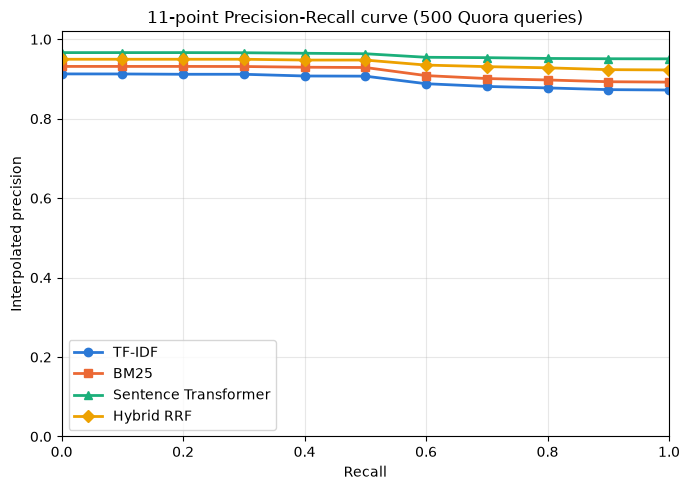

In [15]:
RECALL_LEVELS = np.linspace(0, 1, 11)

def interpolated_pr(ranked, relevant):
    precisions, recalls, hits = [], [], 0
    for i, d in enumerate(ranked, start=1):
        hits += d in relevant
        precisions.append(hits / i)
        recalls.append(hits / len(relevant))
    # interpolated precision = max precision at any recall >= level
    return [max([p for p, r in zip(precisions, recalls) if r >= level], default=0) for level in RECALL_LEVELS]

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
markers = ["o", "s", "^", "D"]

plt.figure(figsize=(7, 5))
for (name, run), color, marker in zip(runs.items(), colors, markers):
    curve = np.mean([interpolated_pr(run[q], qrels[q]) for q in queries], axis=0)
    plt.plot(RECALL_LEVELS, curve, color=color, marker=marker, linewidth=2, markersize=6, label=name)

plt.xlabel("Recall")
plt.ylabel("Interpolated precision")
plt.title("11-point Precision-Recall curve (500 Quora queries)")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("pr_curve.png", dpi=150)
plt.show()

## Step 10: Demo search

Type any question and see the top-5 most similar questions from each model.
Here there is no query ID, so nothing is excluded.

In [16]:
def search(query, k=5):
    tfidf_res, bm25_res, dense_res = search_tfidf(query), search_bm25(query), search_dense(query)
    all_results = {"TF-IDF": tfidf_res[:k], "BM25": bm25_res[:k], "Sentence Transformer": dense_res[:k],
                   "Hybrid RRF": rrf_fuse([tfidf_res, bm25_res, dense_res], k)}
    print("QUERY:", query)
    for name, res in all_results.items():
        print(f"\n--- {name} ---")
        for doc_id, score in res:
            print(f"{score:.4f}  {id_to_text[doc_id]}")

search("What is the best way to lose weight quickly?")

QUERY: What is the best way to lose weight quickly?

--- TF-IDF ---
0.7571  Can I lose weight this way?
0.6982  How can I lose my weight quickly without doing exercise?
0.6356  Why should I lose weight?
0.6344  How can I lose weight quickly? Need serious help.
0.5893  How quickly can I lose a kilogram of weight, and how would I set about doing this?

--- BM25 ---
19.6217  Can I lose weight this way?
18.9532  How can I lose my weight quickly without doing exercise?
17.7115  How can I lose weight quickly? Need serious help.
16.6225  How quickly can I lose a kilogram of weight, and how would I set about doing this?
15.9355  What are the best remedies to lose weight?

--- Sentence Transformer ---
0.8927  How can I lose weight quickly? Need serious help.
0.8441  What's the best diet to lose weight fast?
0.8316  How can you lose weight fast in a healthy way?
0.8124  What can you take to lose weight fast?
0.8055  What is the best remedy for a quick weight loss?

--- Hybrid RRF ---
0.0479  How

In [17]:
search("How can I become a good programmer?")

QUERY: How can I become a good programmer?

--- TF-IDF ---
1.0000  How can I become a good programmer in c#?
0.8107  What can be done to become a good programmer?
0.7788  How do I train a person to become a good programmer?
0.7493  What are the stages of becoming a good programmer?
0.6474  Am I too old to start learning how to program and become a really good programmer?

--- BM25 ---
17.3333  How can I become a good programmer in c#?
16.1182  How do I train a person to become a good programmer?
16.0972  What can be done to become a good programmer?
16.0972  What are the stages of becoming a good programmer?
13.3173  Am I too old to start learning how to program and become a really good programmer?

--- Sentence Transformer ---
0.9547  What can be done to become a good programmer?
0.8786  What are the best steps (1-10) to become a excellent programmer?
0.8457  How do I train a person to become a good programmer?
0.8296  How do I know if I am good enough to be a programmer?
0.8176  What